# 03 · Construcción del Target — Churn Bancario

## Problema detectado en EDA de calidad

El dataset tiene un **desfase en el target** que hay que entender antes de modelar:

| `foto_mes` | `baja2` significa | ¿Tiene label? |
|---|---|---|
| 202103 | cliente se va en 202105 | ✓ sí |
| 202104 | cliente se va en 202106 | ✓ sí |
| 202105 | cliente se va en 202107 | ✓ sí |
| 202106 | cliente se va en 202108 | ✓ sí |
| **202107** | cliente se va en **202109** | **✗ no — sin_target** |
| 202108 | cliente se va en 202110 | ✗ no — sin_target |

**Conclusión**: el último mes con target real usable para entrenar es `202106`.  
El mes `202107` quedó sin etiquetar porque su horizonte de predicción (`202109`) no existe en el dataset.

## Objetivo de este notebook

1. Verificar y documentar la estructura del target mes a mes
2. Construir un **flag binario de churn** limpio para modelado (`es_baja2`)
3. Definir y validar la **función de ganancia** con los montos actuales
4. Guardar el dataset con el target corregido y columnas auxiliares para el walk-forward

---
**Proyecto:** Predicción de Churn Bancario · Data Mining en EyF  
**Etapa:** 3 — Construcción del target  
**Última actualización:** 2026-10

## 0 · Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import gc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

# ─── Rutas ────────────────────────────────────────────────────────────────────
RUTA_BASE    = Path('/content/drive/MyDrive/Maestría Data Mining/DM en EyF')
RUTA_COMP    = RUTA_BASE / 'Competencia 1'
ARCHIVO_RAW  = RUTA_BASE / 'competencia_01.csv'
ARCHIVO_OUT  = RUTA_COMP / 'dataset_target_construido.parquet'   # output principal

# ─── Constantes del dataset (confirmadas en notebooks 01 y 02) ────────────────
COL_ID      = 'numero_de_cliente'
COL_PERIODO = 'foto_mes'
TARGET_RAW  = 'clase_ternaria'

# Meses disponibles
MESES_CON_TARGET = [202103, 202104, 202105, 202106]   # únicos con baja2 real
MES_SIN_TARGET_1 = 202107   # target natural sería 202109 (no existe)
MES_SIN_TARGET_2 = 202108   # mes a predecir en la competencia

# ─── Función de ganancia (edición actual) ─────────────────────────────────────
GANANCIA_TP =  1_072_500   # Cliente BAJA+2 detectado e intervenido
COSTO_FP    =    -27_500   # Costo de intervención en cliente que NO se da de baja
# FN = 0 (no intervenir a alguien que se iba = no ganamos ni perdemos)
# TN = 0 (no intervenir a alguien que se queda = correcto, sin costo)

RATIO_OPTIMO = abs(GANANCIA_TP / COSTO_FP)   # 39 — cuántos FP toleramos por TP
print(f'Ratio TP/FP de equilibrio: {RATIO_OPTIMO:.1f}x')
print(f'Archivos:')
print(f'  Input:  {ARCHIVO_RAW.exists()} → {ARCHIVO_RAW.name}')
print(f'  Output: {RUTA_COMP.exists()} → {ARCHIVO_OUT.name}')

Ratio TP/FP de equilibrio: 39.0x
Archivos:
  Input:  True → competencia_01.csv
  Output: True → dataset_target_construido.parquet


## 1 · Carga optimizada

In [3]:
def inferir_dtypes_optimos(df_muestra, umbral_categorica=0.05):
    dtypes = {}
    for col in df_muestra.columns:
        tipo = df_muestra[col].dtype
        if tipo == 'float64':
            dtypes[col] = 'float32'
        elif tipo == 'int64':
            mn, mx = df_muestra[col].min(), df_muestra[col].max()
            if mn >= 0:
                dtypes[col] = 'uint8' if mx < 256 else 'uint16' if mx < 65536 else 'uint32'
            else:
                dtypes[col] = 'int8' if (mn > -128 and mx < 128) else 'int16' if (mn > -32768 and mx < 32768) else 'int32'
        elif tipo == 'object':
            if df_muestra[col].nunique() / len(df_muestra) < umbral_categorica:
                dtypes[col] = 'category'
    return dtypes

muestra = pd.read_csv(ARCHIVO_RAW, nrows=500)
dtypes_optimos = inferir_dtypes_optimos(muestra)
del muestra; gc.collect()

df = pd.read_csv(ARCHIVO_RAW, dtype=dtypes_optimos, low_memory=False)
mem_mb = df.memory_usage(deep=True).sum() / 1024**2
print(f'Dataset cargado: {df.shape[0]:,} filas × {df.shape[1]} columnas — {mem_mb:.1f} MB')

Dataset cargado: 983,061 filas × 155 columnas — 404.1 MB


## 2 · Verificación de la estructura del target

Confirmamos mes a mes qué valores reales tiene `clase_ternaria`.

In [4]:
# Distribución del target por mes — tabla completa
target_por_mes = (
    df.groupby([COL_PERIODO, TARGET_RAW])
    .size()
    .unstack(fill_value=0)
)
target_pct = target_por_mes.div(target_por_mes.sum(axis=1), axis=0).mul(100).round(2)

print('=== Conteo absoluto por mes ===')
print(target_por_mes.to_string())
print()
print('=== % por mes ===')
print(target_pct.to_string())

=== Conteo absoluto por mes ===
clase_ternaria  baja1  baja2  continua  sin_target
foto_mes                                          
202103           1019    960    160921           0
202104            964   1139    161181           0
202105           1143    870    161755           0
202106            874   1098    162142           0
202107              0      0         0      164348
202108              0      0         0      164647

=== % por mes ===
clase_ternaria  baja1  baja2  continua  sin_target
foto_mes                                          
202103           0.63   0.59     98.79         0.0
202104           0.59   0.70     98.71         0.0
202105           0.70   0.53     98.77         0.0
202106           0.53   0.67     98.80         0.0
202107           0.00   0.00      0.00       100.0
202108           0.00   0.00      0.00       100.0


In [5]:
# Confirmación: ¿qué meses tienen baja2 real?
meses_con_baja2 = (
    df[df[TARGET_RAW] == 'baja2']
    .groupby(COL_PERIODO)
    .size()
    .rename('n_baja2')
)
print('Meses con registros baja2:')
print(meses_con_baja2)

print(f'\nMeses entrenables (tienen baja2): {meses_con_baja2.index.tolist()}')
print(f'Último mes entrenable: {meses_con_baja2.index.max()}')
print(f'Mes a predecir (sin_target): {MES_SIN_TARGET_2}')

Meses con registros baja2:
foto_mes
202103     960
202104    1139
202105     870
202106    1098
Name: n_baja2, dtype: int64

Meses entrenables (tienen baja2): [202103, 202104, 202105, 202106]
Último mes entrenable: 202106
Mes a predecir (sin_target): 202108


## 3 · Construcción del target binario

Para el modelo necesitamos un **target binario** claro:
- `1` = `baja2` (cliente que se da de baja 2 meses después → queremos detectarlos)
- `0` = `continua` (cliente que sigue activo)
- `NaN` = meses sin target real (`202107`, `202108`) → se excluyen del entrenamiento

> **¿Por qué excluimos `baja1`?**  
> `baja1` es un cliente que se va el *mes siguiente*, no dos meses después. La función de ganancia
> los trata igual que `continua` cuando se les aplica el estímulo (son FP = -$27.500).  
> No tienen label positivo en nuestra función objetivo, por lo que no deben entrar como `1`.
> Tampoco los incluimos como `0` (negativo limpio) porque introducen ruido: son clientes
> que *también* se van, solo que antes. La práctica estándar en esta competencia es excluirlos
> del entrenamiento o tratarlos como `continua` — acá los excluimos para tener el target más limpio.

In [6]:
# Construcción del target binario
# Sólo en los meses con target real (MESES_CON_TARGET)
df['es_baja2'] = np.nan   # NaN por defecto

mask_entrenable = df[COL_PERIODO].isin(MESES_CON_TARGET)
mask_baja2      = df[TARGET_RAW] == 'baja2'
mask_continua   = df[TARGET_RAW] == 'continua'
# baja1 queda como NaN dentro del período entrenable (excluida)

df.loc[mask_entrenable & mask_baja2,    'es_baja2'] = 1.0
df.loc[mask_entrenable & mask_continua, 'es_baja2'] = 0.0

# Resumen
resumen = df.groupby(COL_PERIODO)['es_baja2'].value_counts(dropna=False).unstack(fill_value=0)
print('Distribución del target binario por mes:')
print(resumen.rename(columns={0.0: 'continua (0)', 1.0: 'baja2 (1)', np.nan: 'excluido/NaN'}))

total_entrenables = mask_entrenable.sum()
total_baja2       = (df['es_baja2'] == 1).sum()
total_continua    = (df['es_baja2'] == 0).sum()
total_baja1       = (mask_entrenable & (df[TARGET_RAW] == 'baja1')).sum()

print(f'\nFilas para entrenamiento (meses 202103-202106): {total_entrenables:,}')
print(f'  baja2    (target=1): {total_baja2:,} ({total_baja2/total_entrenables*100:.2f}%)')
print(f'  continua (target=0): {total_continua:,} ({total_continua/total_entrenables*100:.2f}%)')
print(f'  baja1    (excluida): {total_baja1:,} ({total_baja1/total_entrenables*100:.2f}%)')

Distribución del target binario por mes:
es_baja2  continua (0)  baja2 (1)     NaN
foto_mes                                 
202103          160921        960    1019
202104          161181       1139     964
202105          161755        870    1143
202106          162142       1098     874
202107               0          0  164348
202108               0          0  164647

Filas para entrenamiento (meses 202103-202106): 654,066
  baja2    (target=1): 4,067 (0.62%)
  continua (target=0): 645,999 (98.77%)
  baja1    (excluida): 4,000 (0.61%)


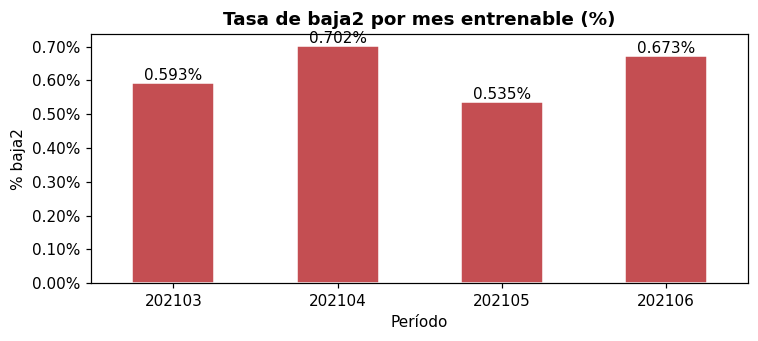

Tasa de churn promedio (baja2): 0.626%


In [7]:
# Tasa de churn real (baja2) por mes entrenable
tasa_baja2 = (
    df[df[COL_PERIODO].isin(MESES_CON_TARGET)]
    .groupby(COL_PERIODO)['es_baja2']
    .mean()
    .mul(100)
    .rename('tasa_baja2_pct')
)

fig, ax = plt.subplots(figsize=(7, 3.2))
tasa_baja2.plot(kind='bar', ax=ax, color='#C44E52', edgecolor='white')
ax.set_title('Tasa de baja2 por mes entrenable (%)', fontsize=12, fontweight='bold')
ax.set_xlabel('Período')
ax.set_ylabel('% baja2')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.2f}%'))
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}%',
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(f'Tasa de churn promedio (baja2): {tasa_baja2.mean():.3f}%')

## 4 · Función de ganancia

Definimos y validamos la función de ganancia con los montos actuales de la competencia.

In [8]:
def calcular_ganancia(y_true: pd.Series, y_pred_binario: pd.Series) -> float:
    """
    Calcula la ganancia total dado el target real y la predicción binaria.

    Parámetros
    ----------
    y_true         : Series con valores 0 (continua) o 1 (baja2). NaN ignorados.
    y_pred_binario : Series binaria (0 = no intervenimos, 1 = intervenimos).

    Retorna
    -------
    ganancia total en pesos
    """
    mask = y_true.notna()
    yt = y_true[mask].astype(int)
    yp = y_pred_binario[mask].astype(int)

    tp = ((yt == 1) & (yp == 1)).sum()   # detectamos baja2 correctamente
    fp = ((yt == 0) & (yp == 1)).sum()   # intervenimos a alguien que no se iba
    fn = ((yt == 1) & (yp == 0)).sum()   # baja2 que no detectamos (costo = 0)
    tn = ((yt == 0) & (yp == 0)).sum()   # no intervenimos y no se iban (costo = 0)

    ganancia = tp * GANANCIA_TP + fp * COSTO_FP

    print(f'TP (baja2 detectados):     {tp:>8,}  → +${tp * GANANCIA_TP:>15,.0f}')
    print(f'FP (intervención en vano): {fp:>8,}  → ${fp * COSTO_FP:>15,.0f}')
    print(f'FN (baja2 no detectados):  {fn:>8,}  →             $0')
    print(f'TN (correcto no enviar):   {tn:>8,}  →             $0')
    print(f'{'─'*50}')
    print(f'GANANCIA TOTAL:            {"":>8}    ${ganancia:>15,.0f}')
    return ganancia


def ganancia_por_threshold(y_true: pd.Series, y_prob: pd.Series,
                           thresholds=None) -> pd.DataFrame:
    """
    Barre thresholds y devuelve la ganancia para cada uno.
    Permite encontrar el threshold óptimo que maximiza la función objetivo.
    """
    if thresholds is None:
        thresholds = np.linspace(0.001, 0.999, 500)

    mask = y_true.notna()
    yt = y_true[mask].astype(int).values
    yp = y_prob[mask].values

    resultados = []
    for t in thresholds:
        pred = (yp >= t).astype(int)
        tp = ((yt == 1) & (pred == 1)).sum()
        fp = ((yt == 0) & (pred == 1)).sum()
        g  = tp * GANANCIA_TP + fp * COSTO_FP
        resultados.append({'threshold': t, 'ganancia': g, 'tp': tp, 'fp': fp,
                           'n_predichos_positivos': tp + fp})

    return pd.DataFrame(resultados)


print('✓ Funciones de ganancia definidas.')
print(f'  GANANCIA_TP = ${GANANCIA_TP:,.0f}')
print(f'  COSTO_FP    = ${COSTO_FP:,.0f}')
print(f'  Ratio de equilibrio: {RATIO_OPTIMO:.1f}x (podemos tener {RATIO_OPTIMO:.0f} FP por cada TP y empatar)')

✓ Funciones de ganancia definidas.
  GANANCIA_TP = $1,072,500
  COSTO_FP    = $-27,500
  Ratio de equilibrio: 39.0x (podemos tener 39 FP por cada TP y empatar)


In [9]:
# Validación: ¿cuánto ganaríamos si predijéramos correctamente a todos los baja2?
# (techo teórico — upper bound de la competencia)
print('=== ESCENARIO TECHO (predictor perfecto) ===')
y_true_todo = df.loc[df[COL_PERIODO].isin(MESES_CON_TARGET), 'es_baja2'].dropna()
y_perfecto  = y_true_todo.copy()
_ = calcular_ganancia(y_true_todo, y_perfecto)

print()
print('=== ESCENARIO NAIVE (predecir siempre 0 = no intervenimos) ===')
y_naive_0 = pd.Series(0, index=y_true_todo.index)
_ = calcular_ganancia(y_true_todo, y_naive_0)

print()
print('=== ESCENARIO NAIVE (predecir siempre 1 = intervenimos a todos) ===')
y_naive_1 = pd.Series(1, index=y_true_todo.index)
_ = calcular_ganancia(y_true_todo, y_naive_1)

=== ESCENARIO TECHO (predictor perfecto) ===
TP (baja2 detectados):        4,067  → +$  4,361,857,500
FP (intervención en vano):        0  → $              0
FN (baja2 no detectados):         0  →             $0
TN (correcto no enviar):    645,999  →             $0
──────────────────────────────────────────────────
GANANCIA TOTAL:                        $  4,361,857,500

=== ESCENARIO NAIVE (predecir siempre 0 = no intervenimos) ===
TP (baja2 detectados):            0  → +$              0
FP (intervención en vano):        0  → $              0
FN (baja2 no detectados):     4,067  →             $0
TN (correcto no enviar):    645,999  →             $0
──────────────────────────────────────────────────
GANANCIA TOTAL:                        $              0

=== ESCENARIO NAIVE (predecir siempre 1 = intervenimos a todos) ===
TP (baja2 detectados):        4,067  → +$  4,361,857,500
FP (intervención en vano):  645,999  → $-17,764,972,500
FN (baja2 no detectados):         0  →             $0

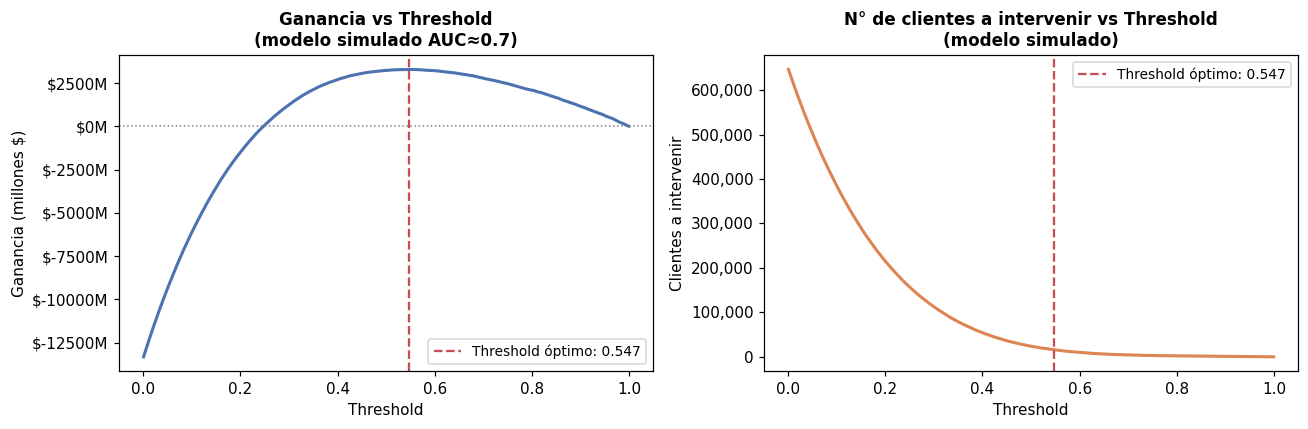


Threshold óptimo (modelo simulado): 0.5470
Ganancia óptima  (modelo simulado): $3,300,192,500

Nota: con el modelo real el threshold óptimo se calculará sobre validación walk-forward.


In [10]:
# Visualización: cómo varía la ganancia con el threshold (ejemplo con prob random)
# Esto ilustra la forma de la curva — con el modelo real será mucho mejor
np.random.seed(42)
n = len(y_true_todo)
# Simulamos un scoring con algo de señal (AUC ~0.7)
y_true_arr = y_true_todo.values
scores_sim = (
    y_true_arr * np.random.beta(3, 1, n) +
    (1 - y_true_arr) * np.random.beta(1, 5, n)
)
y_prob_sim = pd.Series(scores_sim, index=y_true_todo.index)

df_thresh = ganancia_por_threshold(y_true_todo, y_prob_sim)
idx_optimo = df_thresh['ganancia'].idxmax()
thresh_opt = df_thresh.loc[idx_optimo, 'threshold']
ganancia_opt = df_thresh.loc[idx_optimo, 'ganancia']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Ganancia vs threshold
ax = axes[0]
ax.plot(df_thresh['threshold'], df_thresh['ganancia'] / 1e6, color='#4C72B0', linewidth=2)
ax.axvline(thresh_opt, color='#C44E52', linestyle='--', linewidth=1.5,
           label=f'Threshold óptimo: {thresh_opt:.3f}')
ax.axhline(0, color='gray', linestyle=':', linewidth=1)
ax.set_title('Ganancia vs Threshold\n(modelo simulado AUC≈0.7)', fontsize=11, fontweight='bold')
ax.set_xlabel('Threshold')
ax.set_ylabel('Ganancia (millones $)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))
ax.legend(fontsize=9)

# Positivos predichos vs threshold
ax = axes[1]
ax.plot(df_thresh['threshold'], df_thresh['n_predichos_positivos'],
        color='#DD8452', linewidth=2)
ax.axvline(thresh_opt, color='#C44E52', linestyle='--', linewidth=1.5,
           label=f'Threshold óptimo: {thresh_opt:.3f}')
ax.set_title('N° de clientes a intervenir vs Threshold\n(modelo simulado)', fontsize=11, fontweight='bold')
ax.set_xlabel('Threshold')
ax.set_ylabel('Clientes a intervenir')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

print(f'\nThreshold óptimo (modelo simulado): {thresh_opt:.4f}')
print(f'Ganancia óptima  (modelo simulado): ${ganancia_opt:,.0f}')
print(f'\nNota: con el modelo real el threshold óptimo se calculará sobre validación walk-forward.')

## 5 · Columnas auxiliares para el walk-forward

Agregamos columnas que van a ser útiles en cada fold de la validación:
- `es_baja2`: target binario (ya construido)
- `fold_rol`: identifica el rol de cada fila en cada simulación posible
- `mes_anterior`: para join con features lagged

In [11]:
# Mapa de folds posibles para walk-forward
# Cada fold: entrenamos con todos los meses < mes_test, predecimos mes_test
# Solo podemos usar como mes_test meses que tienen target real (MESES_CON_TARGET)

print('Folds de validación disponibles (walk-forward):')
print(f'{"Fold":>5}  {"Mes a predecir":>16}  {"Meses de entrenamiento":>30}  {"N train":>10}  {"N test":>8}')
print('─' * 80)

for i, mes_test in enumerate(MESES_CON_TARGET):
    meses_train = [m for m in MESES_CON_TARGET if m < mes_test]
    if not meses_train:
        print(f'{i+1:>5}  {mes_test:>16}  {"(sin datos previos)":>30}  {"─":>10}  {"─":>8}')
        continue
    n_train = df[
        df[COL_PERIODO].isin(meses_train) & df['es_baja2'].notna()
    ].shape[0]
    n_test  = df[
        (df[COL_PERIODO] == mes_test) & df['es_baja2'].notna()
    ].shape[0]
    meses_str = str(meses_train)
    print(f'{i+1:>5}  {mes_test:>16}  {meses_str:>30}  {n_train:>10,}  {n_test:>8,}')

print()
print('Nota: el fold 1 (mes_test=202103) no tiene meses previos → no se puede usar.')
print('Folds utilizables para validación: 2, 3 y 4 (mes_test = 202104, 202105, 202106)')

Folds de validación disponibles (walk-forward):
 Fold    Mes a predecir          Meses de entrenamiento     N train    N test
────────────────────────────────────────────────────────────────────────────────
    1            202103             (sin datos previos)           ─         ─
    2            202104                        [202103]     161,881   162,320
    3            202105                [202103, 202104]     324,201   162,625
    4            202106        [202103, 202104, 202105]     486,826   163,240

Nota: el fold 1 (mes_test=202103) no tiene meses previos → no se puede usar.
Folds utilizables para validación: 2, 3 y 4 (mes_test = 202104, 202105, 202106)


## 6 · Guardar el dataset procesado

Guardamos en formato **Parquet** dentro de la carpeta de la competencia:  
- Más rápido de leer que CSV
- Preserva dtypes
- ~60-70% menos espacio en disco

In [12]:
# Verificamos que la carpeta de la competencia existe
RUTA_COMP.mkdir(parents=True, exist_ok=True)

# El target es float por los NaN — lo dejamos así, es correcto para sklearn/lgbm
print(f'Columnas nuevas agregadas:')
print(f'  es_baja2: {df["es_baja2"].dtype} | valores: {df["es_baja2"].value_counts(dropna=False).to_dict()}')

# Guardar
df.to_parquet(ARCHIVO_OUT, index=False, engine='pyarrow')

tam_mb = ARCHIVO_OUT.stat().st_size / 1024**2
print(f'\n✓ Dataset guardado en: {ARCHIVO_OUT}')
print(f'  Tamaño en disco: {tam_mb:.1f} MB')
print(f'  Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}')

Columnas nuevas agregadas:
  es_baja2: float64 | valores: {0.0: 645999, nan: 332995, 1.0: 4067}

✓ Dataset guardado en: /content/drive/MyDrive/Maestría Data Mining/DM en EyF/Competencia 1/dataset_target_construido.parquet
  Tamaño en disco: 130.3 MB
  Filas: 983,061 | Columnas: 156


## 7 · Resumen ejecutivo

In [13]:
print('=' * 60)
print('RESUMEN — CONSTRUCCIÓN DEL TARGET')
print('=' * 60)
print()
print('ESTRUCTURA TEMPORAL')
print(f'  Meses totales:          {df[COL_PERIODO].nunique()}')
print(f'  Meses con target real:  {len(MESES_CON_TARGET)} ({MESES_CON_TARGET})')
print(f'  Meses sin target:       2 ({MES_SIN_TARGET_1}, {MES_SIN_TARGET_2})')
print(f'  Mes a predecir:         {MES_SIN_TARGET_2}')
print()
print('TARGET BINARIO (es_baja2)')
print(f'  Positivos (baja2):      {(df["es_baja2"]==1).sum():,}')
print(f'  Negativos (continua):   {(df["es_baja2"]==0).sum():,}')
print(f'  Excluidos (baja1):      {total_baja1:,}')
print(f'  Sin target (NaN):       {df["es_baja2"].isna().sum():,}')
print(f'  Tasa de churn:          {(df["es_baja2"]==1).sum() / (df["es_baja2"].notna()).sum() * 100:.3f}%')
print()
print('FUNCIÓN DE GANANCIA')
print(f'  TP (baja2 detectado):   +${GANANCIA_TP:>12,.0f}')
print(f'  FP (falso positivo):     ${COSTO_FP:>12,.0f}')
print(f'  FN / TN:                           $0')
print(f'  Ratio equilibrio:        {RATIO_OPTIMO:.0f}x FP por TP')
print()
print('VALIDACIÓN WALK-FORWARD')
print(f'  Folds disponibles:      3 (meses 202104, 202105, 202106 como test)')
print(f'  Threshold:              NO es 0.5 — se optimiza barriendo sobre ganancia')
print()
print(f'OUTPUT: {ARCHIVO_OUT.name}')

RESUMEN — CONSTRUCCIÓN DEL TARGET

ESTRUCTURA TEMPORAL
  Meses totales:          6
  Meses con target real:  4 ([202103, 202104, 202105, 202106])
  Meses sin target:       2 (202107, 202108)
  Mes a predecir:         202108

TARGET BINARIO (es_baja2)
  Positivos (baja2):      4,067
  Negativos (continua):   645,999
  Excluidos (baja1):      4,000
  Sin target (NaN):       332,995
  Tasa de churn:          0.626%

FUNCIÓN DE GANANCIA
  TP (baja2 detectado):   +$   1,072,500
  FP (falso positivo):     $     -27,500
  FN / TN:                           $0
  Ratio equilibrio:        39x FP por TP

VALIDACIÓN WALK-FORWARD
  Folds disponibles:      3 (meses 202104, 202105, 202106 como test)
  Threshold:              NO es 0.5 — se optimiza barriendo sobre ganancia

OUTPUT: dataset_target_construido.parquet


In [14]:
del df, y_true_todo, y_prob_sim, df_thresh
gc.collect()
print('✓ Memoria liberada. Target construido y guardado.')

✓ Memoria liberada. Target construido y guardado.
